In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [17]:
def plot_rt_distribution(file_path):

    df = pd.read_csv(file_path, index_col=0)
    df["difficulty"] = df["difficulty"].astype(str)  # so 3-level/5-level cats group properly

    # 1. RT distribution by cue
    fig, ax = plt.subplots(figsize=(6,4))
    for cue, sub in df.groupby("cue"):
        ax.hist(sub["rt"], bins=40, alpha=0.5, label="cue", density=True)
    ax.set_xlabel("RT (s)"); ax.set_ylabel("Density")
    ax.legend(title="Cue"); ax.set_title("RT distribution by cue")
    plt.savefig("../images/rt_distribution_by_cue.png", dpi=300)
    plt.tight_layout(); plt.show()

    # 2. Accuracy vs difficulty, split by cue
    acc_tab = df.groupby(["difficulty","cue"])["acc"].mean().reset_index()
    fig, ax = plt.subplots(figsize=(6,4))
    for cue, sub in acc_tab.groupby("cue"):
        ax.plot(sub["difficulty"], sub["acc"], marker="o", label=cue)
    ax.set_xlabel("Difficulty"); ax.set_ylabel("Accuracy")
    ax.legend(title="Cue"); ax.set_title("Accuracy by difficulty and cue")
    plt.savefig("../images/accuracy_by_difficulty_and_cue.png", dpi=300)
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

    # 3. Speed-accuracy tradeoff scatter (mean RT vs mean acc per condition)
    sat = df.groupby(["difficulty","cue","deadline"]).agg(
        mean_rt=("rt","mean"), mean_acc=("acc","mean")
    ).reset_index()
    fig, ax = plt.subplots(figsize=(6,5))
    for (cue,dl), sub in sat.groupby(["cue","deadline"]):
        ax.scatter(sub["mean_rt"], sub["mean_acc"], label=f"{cue}-{dl}", s=60)
    ax.set_xlabel("Mean RT (s)"); ax.set_ylabel("Mean Accuracy")
    ax.legend(); ax.set_title("Speed-Accuracy Tradeoff")
    plt.savefig("../images/speed_accuracy_tradeoff.png", dpi=300)
    plt.tight_layout(); plt.show()

    # 4. RT CDF by deadline condition
    fig, ax = plt.subplots(figsize=(6,4))
    for dl, sub in df.groupby("deadline"):
        x = np.sort(sub["rt"])
        y = np.arange(1,len(x)+1)/len(x)
        ax.plot(x, y, label=dl)
    ax.set_xlabel("RT (s)"); ax.set_ylabel("Cumulative probability")
    ax.legend(title="Deadline"); ax.set_title("RT CDF by deadline")
    plt.savefig("../images/rt_cdf_by_deadline.png", dpi=300)
    plt.tight_layout(); plt.show()

    # 5. Conditional accuracy function (acc vs RT bin) - diagnostic for boundary collapse
    df["rt_bin"] = pd.qcut(df["rt"], 10, duplicates="drop")
    caf = df.groupby(["rt_bin","cue"])["acc"].mean().reset_index()
    caf["rt_mid"] = caf["rt_bin"].apply(lambda x: x.mid)
    fig, ax = plt.subplots(figsize=(6,4))
    for cue, sub in caf.groupby("cue"):
        ax.plot(sub["rt_mid"], sub["acc"], marker="o", label=cue)
    ax.set_xlabel("RT bin (median)"); ax.set_ylabel("Accuracy")
    ax.legend(title="Cue"); ax.set_title("Conditional Accuracy Function")
    plt.savefig("../images/conditional_accuracy_function.png", dpi=300)
    plt.tight_layout(); plt.show()
   

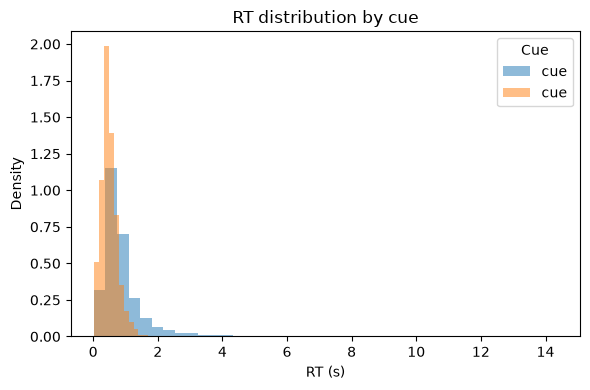

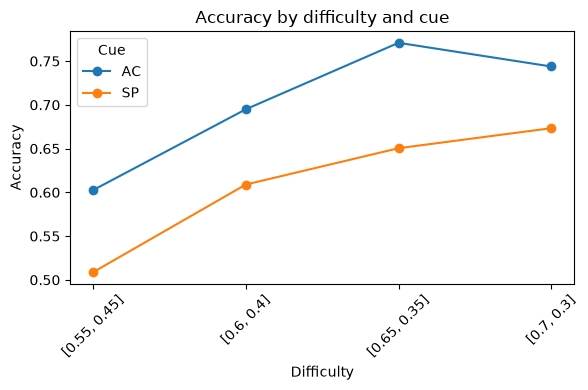

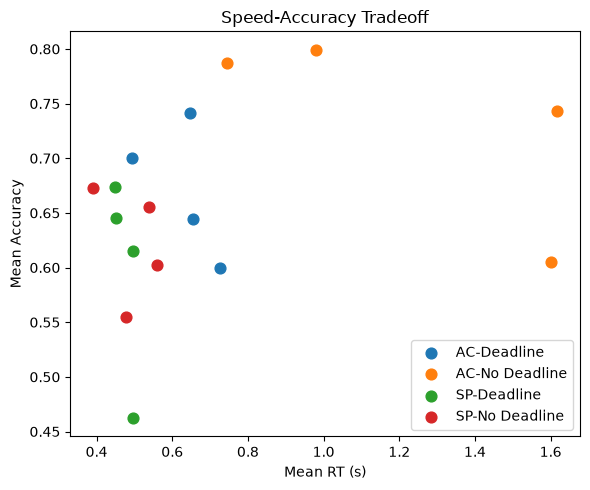

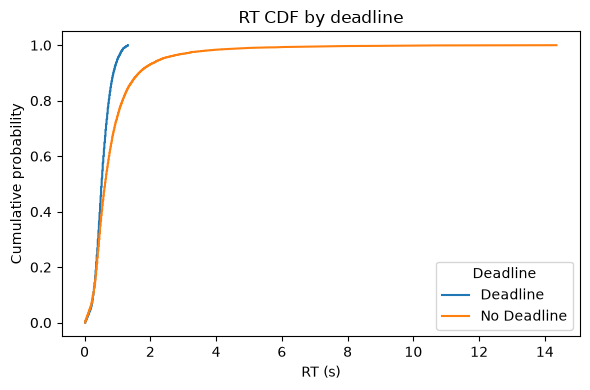

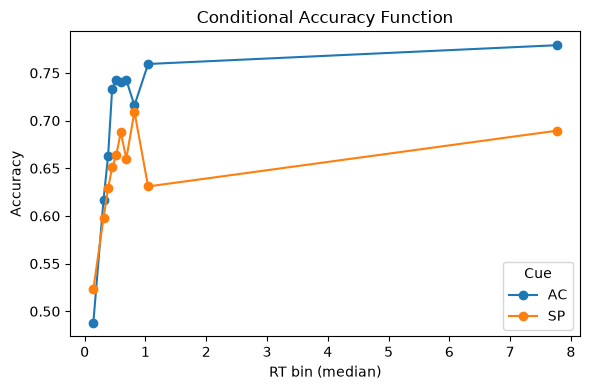

In [18]:
plot_rt_distribution("../data/katsimposis/experiment-2-Flash.csv")




In [19]:
def find_max_mean_min_rt(file_path):
    df = pd.read_csv(file_path, index_col=0)
    max_rt = df["rt"].max()
    min_rt = df["rt"].min()
    mean_rt = df["rt"].mean()
    print(f"{file_path}: Max RT: {max_rt}, Min RT: {min_rt}, Mean RT: {mean_rt}")
    return max_rt


In [20]:
find_max_mean_min_rt("../data/katsimposis/experiment-2-Flash.csv")
find_max_mean_min_rt("../data/katsimposis/experiment-1-RDM.csv")
find_max_mean_min_rt("../data/simulated_data_exponential.csv")

../data/katsimposis/experiment-2-Flash.csv: Max RT: 14.3510980455, Min RT: 0.0179635241875, Mean RT: 0.7150668351881674
../data/katsimposis/experiment-1-RDM.csv: Max RT: 9.89298583003, Min RT: 0.00956473180577, Mean RT: 0.6036762659968163
../data/simulated_data_exponential.csv: Max RT: 3.377615924081484, Min RT: 0.2633094375165576, Mean RT: 0.6703593263858552


np.float64(3.377615924081484)

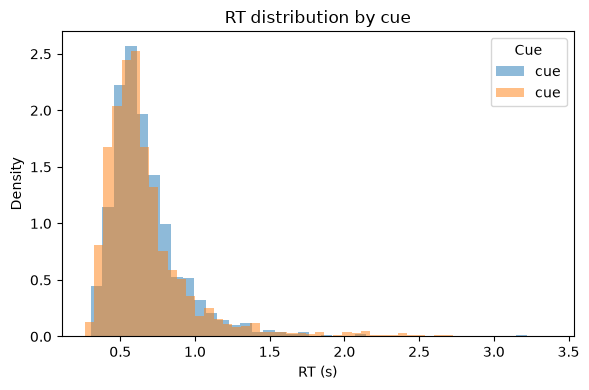

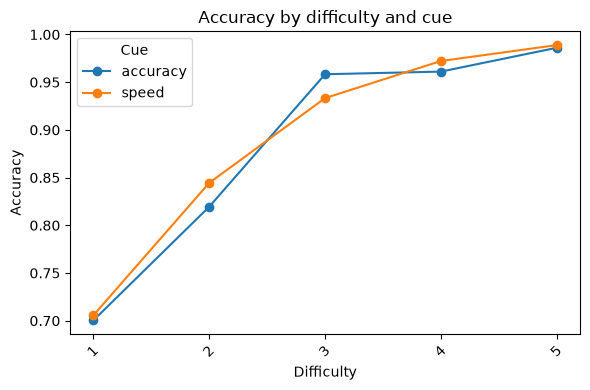

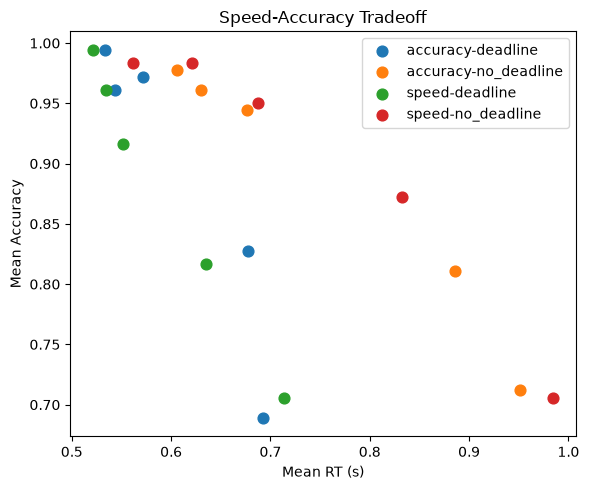

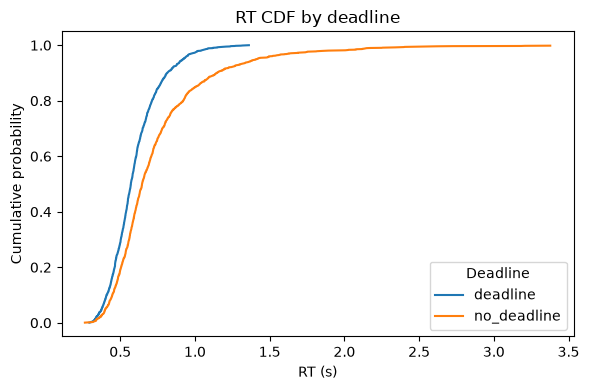

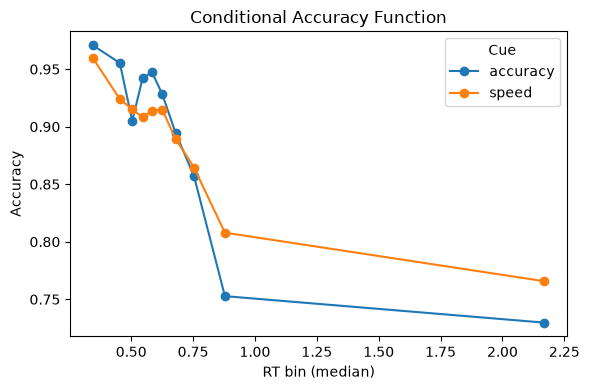

In [21]:
plot_rt_distribution("../data/simulated_data_exponential.csv")